# 02 — House Price Regression: OLS, overfitting, Ridge, and Lasso

**TL;DR.** On the 1,460-row Ames housing dataset (79 predictors, target = sale price), a
three-feature OLS baseline gets a holdout R² of **0.812** and an RMSE of **$35,978**. Adding
engineered features and one-hot encoding lifts that to **R² 0.913 / RMSE $22,788 / MAE $15,195**.
Cross-validated Ridge and Lasso **do not beat OLS on this particular holdout** (R² 0.901 and 0.899),
but they cut 5-fold CV log-RMSE from **0.163 to 0.140 / 0.138**, shrink unstable coefficients, and
let Lasso keep only **80 of 297** encoded features. The honest lesson: with 1,460 rows and a strong
signal, regularization buys stability and simplicity more than raw accuracy.

*Portfolio project 02 of 07 · linear regression, feature engineering, overfitting, Ridge, Lasso.*

## 1. What this notebook does

The goal is to predict a house's sale price from its characteristics, and to use that task to
practise three things that matter in every regression project:

1. **Baseline first.** A model is only impressive relative to something simple.
2. **Overfitting is a gap, not a vibe.** I measure train vs test performance and show a deliberately
   overfit model so the failure mode is visible.
3. **Regularization is a dial, not a magic trick.** Ridge and Lasso change the bias-variance
   trade-off; I tune the dial with cross-validation and then check what it actually bought me.

The notebook is written so that each modelling choice is explained before the code that makes it.

## 2. The problem, and why it matters

House price prediction is the "hello world" of regression, but the underlying task is real:
valuations, lending decisions, property-tax assessments, and investment screens all depend on
estimating what a property is worth from observable characteristics.

The Ames dataset is a modern replacement for the classic Boston Housing data, with a much richer set
of features: lot size, neighbourhood, quality ratings, basement and garage details, porches, sale
conditions, and so on. It is small (1,460 training rows) and mostly complete, which makes it a good
laboratory for the bias-variance question: with more features than rows per feature, an unrestricted
linear model can memorise noise.

The practical question is not "can I get R² above 0.9?" but "which model would I trust on a new
house, and why?". That is why I report a holdout set, cross-validation, and dollar errors rather
than a single leaderboard number.

## 3. Data

**Source:** Ames Housing, distributed as the Kaggle competition
[House Prices — Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques).
The same 1,460-row training table is available through OpenML dataset `42165` (`house_prices`),
which is how I fetched it.

**Licence:** check the Kaggle competition rules and the Ames data documentation before redistributing.
The CSV is **not committed** here; `data/` is git-ignored.

**How to get it:**

```bash
# Option A: Kaggle CLI (needs an account with the competition rules accepted)
kaggle competitions download -c house-prices-advanced-regression-techniques -p data/
unzip data/house-prices-advanced-regression-techniques.zip -d data/

# Option B: OpenML, no Kaggle account
python - <<'PY'
from sklearn.datasets import fetch_openml
d = fetch_openml(data_id=42165, as_frame=True, parser="auto", data_home=".cache/openml")
d.frame.to_csv("data/ames.csv", index=False)
PY
```

**What one row is:** one house sale. The target is `SalePrice`, in US dollars. The features describe
the house, the lot, the neighbourhood, and the sale. There are 1,460 rows and 81 columns including
the target and an `Id`.

**Time period:** the Ames data covers sales in Ames, Iowa, mostly 2006–2010. Any conclusion is about
that market, not about house prices today.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

NAVY, TEAL, ORANGE, GOLD, GRAY = "#12355B", "#1B998B", "#E07A5F", "#F2CC8F", "#6B7280"

In [2]:
DATA = Path("data/ames.csv")
if not DATA.exists():
    raise FileNotFoundError(
        "Missing data/ames.csv. See the download instructions in the README or the cell above."
    )

raw = pd.read_csv(DATA)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw[["Id", "Neighborhood", "OverallQual", "GrLivArea", "YearBuilt", "SalePrice"]].head()

1,460 rows x 81 columns


,Id,Neighborhood,OverallQual,GrLivArea,YearBuilt,SalePrice
0,1,CollgCr,7,1710,2003,208500
1,2,Veenker,6,1262,1976,181500
2,3,CollgCr,7,1786,2001,223500
3,4,Crawfor,7,1717,1915,140000
4,5,NoRidge,8,2198,2000,250000


### 3.1 The target is right-skewed

Sale prices range from about $35k to $755k, with a mean of $181k and a median of $163k. The mean is
above the median, and the maximum is far from the bulk of the data: that is a right-skewed
distribution. A few expensive houses would dominate a model fitted to raw dollars.

The standard fix is to model `log(1 + SalePrice)`. This has three effects:

- It compresses the expensive tail, so the model does not chase a handful of $700k houses.
- It makes the errors multiplicative: a $10k miss on a $100k house and a $20k miss on a $200k house
  count similarly. That matches how valuation errors are usually judged.
- It usually makes the residuals closer to symmetric, which helps the linear model's assumptions.

The cost is that predictions come back on the log scale and must be transformed to dollars. I do
that for evaluation, and I flag the back-transform bias in the limitations.

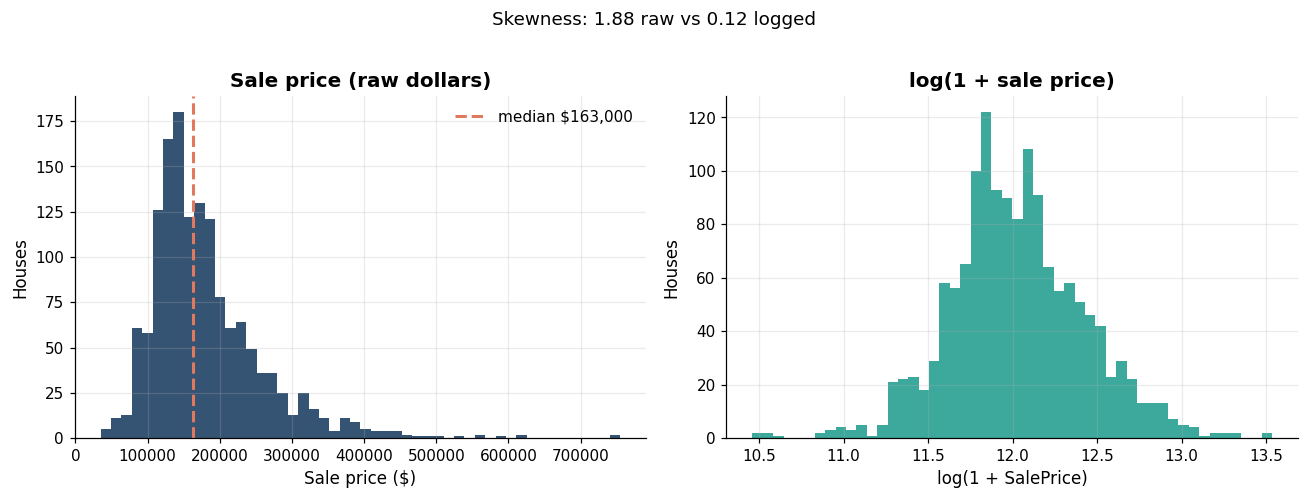

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

axes[0].hist(raw["SalePrice"], bins=50, color=NAVY, alpha=0.85)
axes[0].axvline(raw["SalePrice"].median(), color=ORANGE, lw=2, ls="--",
                label=f"median ${raw['SalePrice'].median():,.0f}")
axes[0].set_title("Sale price (raw dollars)")
axes[0].set_xlabel("Sale price ($)")
axes[0].set_ylabel("Houses")
axes[0].legend(frameon=False)

axes[1].hist(np.log1p(raw["SalePrice"]), bins=50, color=TEAL, alpha=0.85)
axes[1].set_title("log(1 + sale price)")
axes[1].set_xlabel("log(1 + SalePrice)")
axes[1].set_ylabel("Houses")

fig.suptitle(f"Skewness: {raw['SalePrice'].skew():.2f} raw vs {np.log1p(raw['SalePrice']).skew():.2f} logged",
             y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

### 3.2 Missing values are mostly "this feature does not exist"

Nineteen columns have missing values. Many of them are not data-quality problems at all: a missing
`PoolQC` usually means the house has no pool, a missing `Alley` means it has no alley access, and a
missing `GarageType` means it has no garage. Treating those as "unknown" and imputing the most
frequent category would create a fake group of houses that have a garage of unknown type.

The exceptions are columns like `LotFrontage` (genuinely not measured for some parcels) and
`Electrical` (one missing value). I handle those separately.

I list the missing counts because the cleaning code that follows is only understandable in light of
them.

In [4]:
missing = (
    raw.isna().sum()
       .loc[lambda s: s > 0]
       .sort_values(ascending=False)
       .to_frame("missing_count")
)
missing["missing_pct"] = (missing["missing_count"] / len(raw)).map(lambda x: f"{x:.1%}")
missing

,missing_count,missing_pct
PoolQC,1453,99.5%
MiscFeature,1406,96.3%
Alley,1369,93.8%
Fence,1179,80.8%
MasVnrType,872,59.7%
FireplaceQu,690,47.3%
LotFrontage,259,17.7%
GarageType,81,5.5%
GarageYrBlt,81,5.5%
GarageFinish,81,5.5%


The big ones — `PoolQC`, `MiscFeature`, `Alley`, `Fence` — are almost always absent-by-design
features. `LotFrontage` is 17.7% missing and is a real measurement gap; I impute it with the median.
A more careful version would impute it by neighbourhood, because frontage is strongly location-
dependent.

### 3.3 Cleaning and feature engineering

I make the following decisions, all before looking at the test set:

**Drop `Id`.** It is a row identifier, not a feature. Keeping it would let the model learn an
arbitrary ordering.

**Map ordinal quality columns to numbers.** `ExterQual`, `KitchenQual`, `BsmtQual`, etc. use the
ordered labels `Ex > Gd > TA > Fa > Po`. One-hot encoding would throw away that order. I map them to
5, 4, 3, 2, 1 and use 0 for "not present" (which is what the missing value means for these columns).

**Fix absence-missing numeric columns.** `GarageYrBlt` is missing when there is no garage; I fill it
with `YearBuilt` so the year is at least plausible. `MasVnrArea` is missing when there is no masonry
veneer; I fill it with 0.

**Create a few interpretable features.** Raw columns such as `1stFlrSF` and `2ndFlrSF` are pieces of
the same house. A model with 10 correlated size columns has unstable coefficients; a few combined
features are easier to interpret and often predict better:
- `TotalSF` = basement + first floor + second floor
- `TotalBath` = full baths + 0.5 × half baths + basement baths
- `HouseAge` = year sold − year built
- `RemodAge` = year sold − year remodelled
- `TotalPorch` = open + enclosed + 3-season + screened porch
- `HasPool`, `HasGarage` = binary presence flags

**Treat pseudo-numeric columns as categorical.** `MSSubClass` (building class), `MoSold` (month
sold), and `YrSold` are stored as integers but are not continuous quantities. Treating them as
numbers implies that class 120 is "twice" class 60, which is meaningless. I cast them to strings.

**Impute inside the pipeline.** Numeric gaps get the training-fold median, categorical gaps become
`"None"`. Doing this inside a scikit-learn pipeline means the imputation is fitted only on training
data in every CV fold, so there is no leakage.

In [5]:
QUALITY_MAP = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1}
ORDINAL_QUALITY = [
    "ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
    "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC",
]


def prepare_ames(df):
    """Clean, engineer features, and return (X, y) with y on the log1p scale."""
    df = df.copy().drop(columns=["Id"])
    y = np.log1p(df.pop("SalePrice"))

    # Ordinal quality: Ex > Gd > TA > Fa > Po; missing means "not present" -> 0
    for col in ORDINAL_QUALITY:
        df[col] = df[col].map(QUALITY_MAP).fillna(0)

    # Absence-missing numeric fields
    df["GarageYrBlt"] = df["GarageYrBlt"].fillna(df["YearBuilt"])
    df["MasVnrArea"] = df["MasVnrArea"].fillna(0)

    # Interpretable aggregates
    df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
    df["TotalBath"] = (
        df["FullBath"] + 0.5 * df["HalfBath"]
        + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"]
    )
    df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
    df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]
    df["TotalPorch"] = (
        df["OpenPorchSF"] + df["EnclosedPorch"] + df["3SsnPorch"] + df["ScreenPorch"]
    )
    df["HasPool"] = (df["PoolArea"] > 0).astype(int)
    df["HasGarage"] = (df["GarageArea"] > 0).astype(int)

    # Pseudo-numeric columns are really categories
    for col in ["MSSubClass", "MoSold", "YrSold"]:
        df[col] = df[col].astype(str)

    return df, y


X, y = prepare_ames(raw)
numeric_cols = [c for c in X.columns if X[c].dtype != "object"]
categorical_cols = [c for c in X.columns if X[c].dtype == "object"]

print(f"Features: {X.shape[1]} ({len(numeric_cols)} numeric, {len(categorical_cols)} categorical)")
print(f"Target:   {y.shape[0]:,} rows, log1p scale")
X[["GrLivArea", "TotalSF", "TotalBath", "HouseAge", "RemodAge", "HasPool"]].head()

Features: 86 (50 numeric, 36 categorical)
Target:   1,460 rows, log1p scale


,GrLivArea,TotalSF,TotalBath,HouseAge,RemodAge,HasPool
0,1710,2566,3.50,5,5,0
1,1262,2524,2.50,31,31,0
2,1786,2706,3.50,7,6,0
3,1717,2473,2.00,91,36,0
4,2198,3343,3.50,8,8,0


### 3.4 Which features move price?

Two views are useful before modelling:

- **OverallQual vs sale price**: the quality rating is ordinal but strongly related to price.
- **GrLivArea vs sale price**: above-ground living area is the most obvious size measure, and it
  shows both the positive relationship and the outliers.

I also print the strongest linear correlations to get a rough ranking. Correlations are only a first
look: they miss non-linear relationships and interactions, and they can be inflated by confounding
(e.g. quality and size rise together).

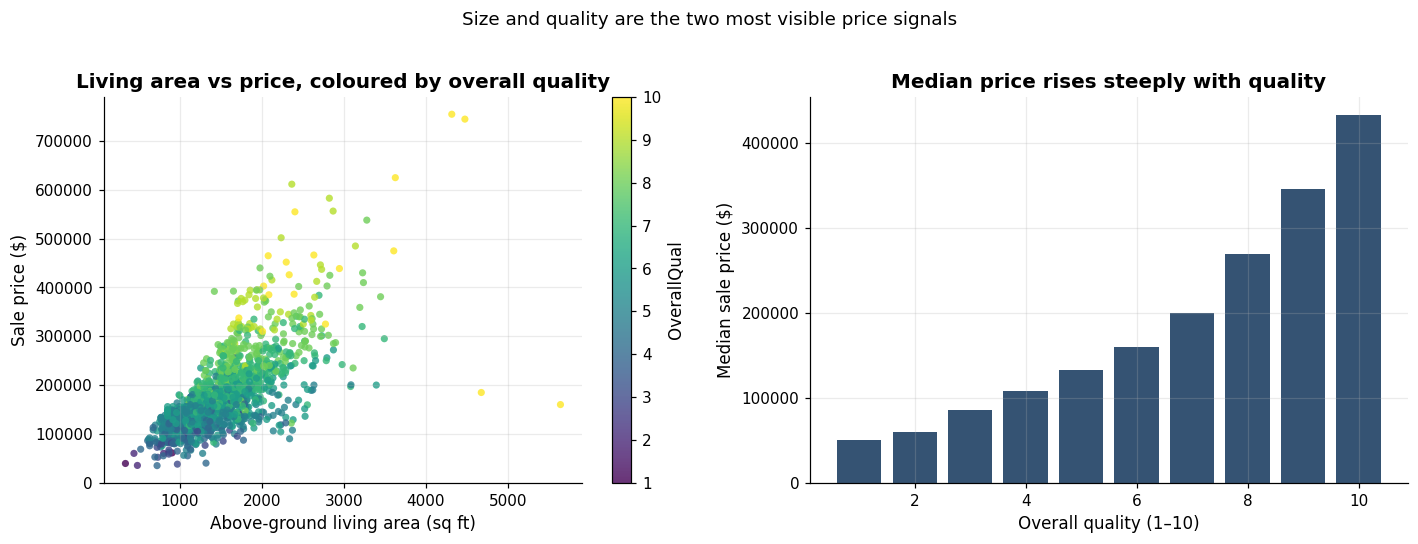

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sc = axes[0].scatter(
    raw["GrLivArea"], raw["SalePrice"], c=raw["OverallQual"],
    cmap="viridis", s=22, alpha=0.8, linewidths=0
)
axes[0].set_xlabel("Above-ground living area (sq ft)")
axes[0].set_ylabel("Sale price ($)")
axes[0].set_title("Living area vs price, coloured by overall quality")
fig.colorbar(sc, ax=axes[0], label="OverallQual")

quality_medians = raw.groupby("OverallQual")["SalePrice"].median()
axes[1].bar(quality_medians.index, quality_medians.values, color=NAVY, alpha=0.85)
axes[1].set_xlabel("Overall quality (1–10)")
axes[1].set_ylabel("Median sale price ($)")
axes[1].set_title("Median price rises steeply with quality")

fig.suptitle("Size and quality are the two most visible price signals", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

In [7]:
corr = (
    raw.select_dtypes("number").corr()["SalePrice"]
       .drop("SalePrice")
       .sort_values(ascending=False)
)
top_corr = pd.concat([corr.head(8), corr.tail(4)]).to_frame("correlation_with_SalePrice")
top_corr["correlation_with_SalePrice"] = top_corr["correlation_with_SalePrice"].round(3)
top_corr

,correlation_with_SalePrice
OverallQual,0.79
GrLivArea,0.71
GarageCars,0.64
GarageArea,0.62
TotalBsmtSF,0.61
1stFlrSF,0.61
FullBath,0.56
TotRmsAbvGrd,0.53
OverallCond,-0.08
MSSubClass,-0.08


`OverallQual` (0.79) and `GrLivArea` (0.71) dominate, followed by garage capacity and area,
basement size, and first-floor area. That is not surprising: quality and size are what buyers pay
for. The negative correlations at the bottom are mostly features that are rare in expensive homes
or encode a condition (e.g. a partial sale).

The scatter also shows two unusual points: very large houses with relatively low sale prices. These
are partial sales, where only a share of the property changed hands. They are legitimate records, so
I keep them, but they will hurt any model that equates size with price. I mention them in the
limitations rather than quietly deleting them.

## 4. Models

### 4.1 The plan

| Model | What it is | Why |
|---|---|---|
| Baseline | OLS on `GrLivArea`, `OverallQual`, `YearBuilt` | A defensible, explainable starting point |
| Full OLS | OLS on all engineered + one-hot features | The best "plain" linear model |
| Ridge | L2 penalty, alpha tuned by 5-fold CV | Shrinks coefficients, stabilises collinear features |
| Lasso | L1 penalty, alpha tuned by 5-fold CV | Shrinks some coefficients exactly to zero |

All models see the same 80/20 split (random_state=42) and the same preprocessing. That makes the
comparison fair: differences come from the model, not from a different train/test split.

### 4.2 Why a baseline?

The three-feature baseline is not a straw man. `GrLivArea`, `OverallQual`, and `YearBuilt` are the
three things an appraiser would ask for first, and they are available for almost every house. If the
297-feature model cannot beat them by a meaningful margin, the extra complexity is not paying for
itself. A baseline also gives me a reference for the dollar errors: "the RMSE fell from $36k to
$23k" is easier to act on than "R² improved by 0.10".

### 4.3 Why regularize?

With 1,460 rows and hundreds of one-hot columns, some coefficients are estimated from very little
data. Correlated features (size, bedrooms, bathrooms) can get large coefficients with opposite signs
that cancel each other out. That model may fit the training data well and generalise poorly.

- **Ridge** adds `alpha * sum(beta²)` to the loss. It shrinks all coefficients toward zero, but
  rarely to exactly zero. It is the right tool when many features are useful but correlated.
- **Lasso** adds `alpha * sum(|beta|)`. It can set coefficients to exactly zero, so it doubles as
  feature selection. It is the right tool when only a few features matter, or when I need a smaller
  model.
- **Alpha** controls the strength. Alpha = 0 is OLS; large alpha approaches a constant prediction.
  I choose it by cross-validation on the *training* set, never on the test set.

Because the penalty is scale-dependent, the numeric features must be standardised first. I do that
inside the pipeline.

### 4.4 A controlled look at overfitting

Before fitting the real models, I want to *see* overfitting rather than just assert it. I take a
random 200-house subset of the training data and fit polynomial regressions of increasing degree on
a single feature (`GrLivArea`). Low degree underfits; high degree can fit the 200 points almost
perfectly but behaves wildly on the held-out houses.

This is a deliberately small sample. The point is the shape of the curve, not the exact numbers.

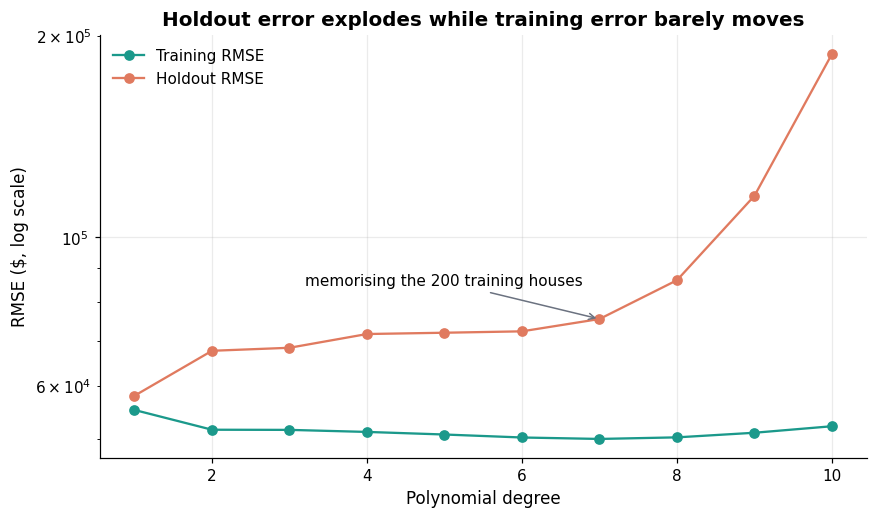

,degree,train_RMSE_$,holdout_RMSE_$
0,1,"55,183.00","57,951.00"
1,2,"51,555.00","67,654.00"
2,3,"51,528.00","68,360.00"
3,4,"51,166.00","71,675.00"
4,5,"50,712.00","71,993.00"
5,6,"50,195.00","72,339.00"
6,7,"49,944.00","75,477.00"
7,8,"50,219.00","86,262.00"
8,9,"51,022.00","115,373.00"
9,10,"52,177.00","187,985.00"


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

rng = np.random.default_rng(42)
subset = rng.choice(len(X_train), size=200, replace=False)
x_small = X_train.iloc[subset][["GrLivArea"]]
y_small = y_train.iloc[subset]

degrees = range(1, 11)
train_rmse, test_rmse = [], []

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression(),
    )
    model.fit(x_small, y_small)
    train_rmse.append(np.sqrt(mean_squared_error(np.exp(y_small), np.exp(model.predict(x_small)))))
    test_rmse.append(np.sqrt(mean_squared_error(np.exp(y_test), np.exp(model.predict(X_test[["GrLivArea"]])))))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(list(degrees), train_rmse, marker="o", color=TEAL, label="Training RMSE")
ax.plot(list(degrees), test_rmse, marker="o", color=ORANGE, label="Holdout RMSE")
ax.set_yscale("log")
ax.set_xlabel("Polynomial degree")
ax.set_ylabel("RMSE ($, log scale)")
ax.set_title("Holdout error explodes while training error barely moves")
ax.legend(frameon=False)
ax.annotate("memorising the 200 training houses", xy=(7, test_rmse[6]),
            xytext=(3.2, max(test_rmse) * 0.45), fontsize=10,
            arrowprops=dict(arrowstyle="->", color=GRAY))
plt.show()

pd.DataFrame({
    "degree": list(degrees),
    "train_RMSE_$": np.round(train_rmse, 0),
    "holdout_RMSE_$": np.round(test_rmse, 0),
})

This is the classic overfitting picture. Training error falls (or stays flat) as the model gets more
flexible, while holdout error rises sharply after degree 3–4. The model is not learning the price
relationship anymore; it is learning the idiosyncrasies of 200 houses.

The same mechanism operates in the full OLS model, just less dramatically: 297 encoded features on
1,168 training rows gives the model enough freedom to fit noise. Regularization is a way to buy back
some of that freedom.

## 5. Fitting the models

### 5.1 Preprocessing pipeline

The preprocessing is the same for every model:

- **Numeric:** median imputation, then standardisation. Standardisation is required for Ridge and
  Lasso, and harmless for OLS.
- **Categorical:** constant imputation (`"None"`), then one-hot encoding. `handle_unknown="ignore"`
  means a category that appears only in the test set becomes all zeros rather than an error.

All of it lives inside a `Pipeline`, so it is refitted inside every CV fold.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="None")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_cols),
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)


def evaluate(name, model, cols=None):
    """Fit, predict, and return dollar and log-scale metrics for the holdout set."""
    Xt = X_train if cols is None else X_train[cols]
    Xv = X_test if cols is None else X_test[cols]

    model.fit(Xt, y_train)
    pred_log = model.predict(Xv)
    train_log = model.predict(Xt)

    actual = np.exp(y_test)
    pred = np.exp(pred_log)

    return {
        "model": name,
        "train_R2": r2_score(y_train, train_log),
        "holdout_R2": r2_score(y_test, pred_log),
        "holdout_RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "holdout_MAE": mean_absolute_error(actual, pred),
        "holdout_MAPE": np.median(np.abs(pred - actual) / actual),
    }

### 5.2 Baseline and full OLS

The baseline uses only three columns, so it needs its own tiny pipeline (impute + OLS). The full OLS
uses every engineered feature. I fit both and compare train and holdout performance. The gap between
train and holdout is the first diagnostic: a large gap means the model is fitting noise.

In [10]:
baseline = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression(),
)

baseline_result = evaluate(
    "Baseline (3 features)", baseline,
    cols=["GrLivArea", "OverallQual", "YearBuilt"],
)

ols_result = evaluate("Full OLS", make_pipeline(preprocess, LinearRegression()))

pd.DataFrame([baseline_result, ols_result]).set_index("model").round(3)

,train_R2,holdout_R2,holdout_RMSE,holdout_MAE,holdout_MAPE
model,,,,,
Baseline (3 features),0.77,0.81,"35,977.70","23,608.92",0.10
Full OLS,0.94,0.91,"22,787.51","15,194.92",0.06


The baseline is already strong: R² 0.812 on the holdout with three features. That is a useful
reminder that most of the signal in this dataset is concentrated in size and quality.

The full OLS improves the holdout R² to 0.913 and cuts RMSE from $35,978 to $22,788. But look at
the training R²: it is 0.945, versus 0.913 on the holdout. The model is fitting about three
percentage points of noise. That gap is the overfitting the regularization is meant to address.

### 5.3 Choosing Ridge and Lasso strength by cross-validation

I search a grid of alphas using 5-fold CV on the training set only. The score is RMSE on the log
scale: it is on the same scale as the target, it is less sensitive to the dollar tail than raw
RMSE, and it is what the models are actually optimising.

The grid is deliberately coarse. A finer grid would produce a more precise alpha, but the exact
value matters less than the order of magnitude; and with 1,460 rows, a very precise alpha is
false precision.

In [11]:
ridge_pipe = Pipeline([("preprocess", preprocess), ("ridge", Ridge())])
lasso_pipe = Pipeline([("preprocess", preprocess), ("lasso", Lasso(max_iter=50000))])

ridge_search = GridSearchCV(
    ridge_pipe,
    {"ridge__alpha": [0.1, 0.3, 1, 3, 10, 30, 100]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
lasso_search = GridSearchCV(
    lasso_pipe,
    {"lasso__alpha": [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)

ridge_search.fit(X_train, y_train)
lasso_search.fit(X_train, y_train)

print(f"Ridge best alpha: {ridge_search.best_params_['ridge__alpha']:.3g}"
      f"  |  CV log-RMSE: {-ridge_search.best_score_:.4f}")
print(f"Lasso best alpha: {lasso_search.best_params_['lasso__alpha']:.3g}"
      f"  |  CV log-RMSE: {-lasso_search.best_score_:.4f}")

# OLS with the same folds, for an apples-to-apples CV comparison
ols_cv_rmse = -cross_val_score(
    make_pipeline(preprocess, LinearRegression()),
    X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error",
).mean()
print(f"OLS CV log-RMSE:  {ols_cv_rmse:.4f}")

Ridge best alpha: 30  |  CV log-RMSE: 0.1401
Lasso best alpha: 0.001  |  CV log-RMSE: 0.1383


OLS CV log-RMSE:  0.1630


### 5.4 The coefficient path

A useful way to see what Ridge does is to plot each coefficient as a function of alpha. At alpha
near zero, the coefficients are the OLS estimates: some are large and have opposite signs because
the features are collinear. As alpha grows, they shrink smoothly toward zero. The path is not a
proof of anything, but it makes the trade-off visible: larger alpha means a simpler model and more
bias.

I fit the path on the already-transformed training matrix so the x-axis is the actual penalty
strength, not a pipeline detail.

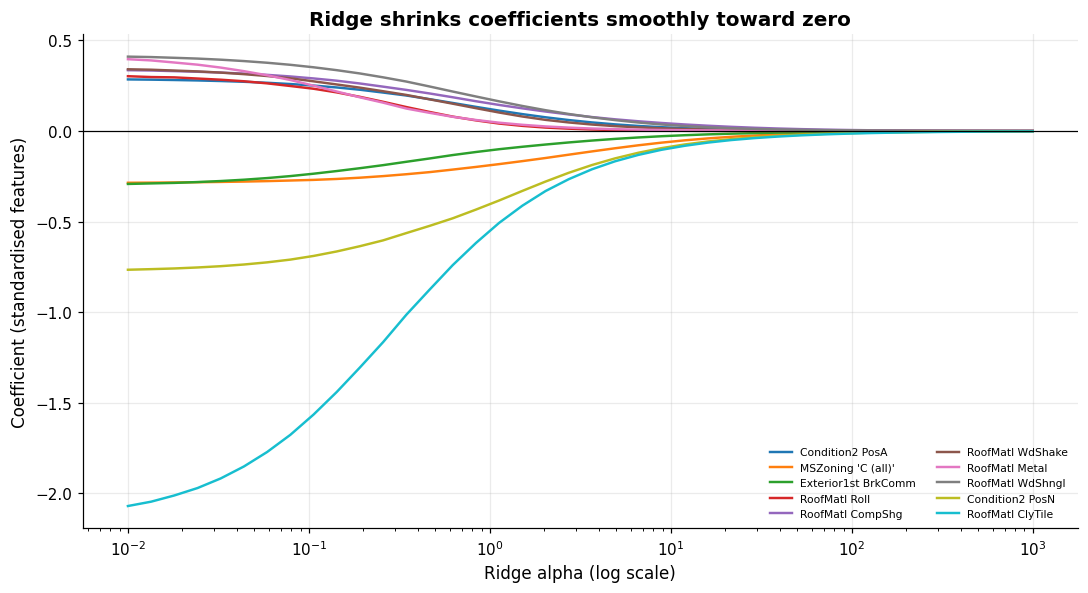

In [12]:
alphas = np.logspace(-2, 3, 40)
X_train_scaled = preprocess.fit_transform(X_train)
feature_names = preprocess.get_feature_names_out()

paths = []
for alpha in alphas:
    ridge = Ridge(alpha=alpha).fit(X_train_scaled, y_train)
    paths.append(ridge.coef_)
paths = np.array(paths)

# Show the features whose coefficients move the most across the path
variation = np.abs(paths).max(axis=0)
top_idx = np.argsort(variation)[-10:]

fig, ax = plt.subplots(figsize=(10, 5.5))
for idx in top_idx:
    label = feature_names[idx].replace("num__", "").replace("cat__", "").replace("_", " ")
    ax.plot(alphas, paths[:, idx], lw=1.6, label=label[:34])
ax.set_xscale("log")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Ridge alpha (log scale)")
ax.set_ylabel("Coefficient (standardised features)")
ax.set_title("Ridge shrinks coefficients smoothly toward zero")
ax.legend(fontsize=7, ncol=2, frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

The largest paths belong to rare categorical dummies — roof material, condition, exterior finish —
which get huge, unstable coefficients when alpha is small and are shrunk hardest as alpha grows.
Interpretable size and quality features also shrink, but they start from smaller values and remain
stable across the path. That contrast is the point: Ridge is not just "making everything smaller",
it is pulling in the coefficients that are least supported by the data.

The path also shows why alpha matters: at the left edge the model is flexible and some coefficients
are extreme; at the right edge everything is compressed toward zero and the model underfits.

The CV-selected alpha is somewhere in the middle. It is not chosen to make the plot look nice; it is
chosen because it minimised average held-out error across five folds.

### 5.5 Holdout comparison

Now I fit OLS, Ridge, and Lasso on the full training set and evaluate them on the same holdout. The
CV-selected alphas are used as-is. I am not re-tuning on the holdout.

In [13]:
ols_result = evaluate("OLS", make_pipeline(preprocess, LinearRegression()))
ridge_result = evaluate("Ridge (CV alpha)", ridge_search.best_estimator_)
lasso_result = evaluate("Lasso (CV alpha)", lasso_search.best_estimator_)

comparison = pd.DataFrame([baseline_result, ols_result, ridge_result, lasso_result])
comparison = comparison.set_index("model")
comparison["holdout_RMSE"] = comparison["holdout_RMSE"].map(lambda x: f"${x:,.0f}")
comparison["holdout_MAE"] = comparison["holdout_MAE"].map(lambda x: f"${x:,.0f}")
comparison["holdout_MAPE"] = comparison["holdout_MAPE"].map(lambda x: f"{x:.1%}")
comparison.round(3)

,train_R2,holdout_R2,holdout_RMSE,holdout_MAE,holdout_MAPE
model,,,,,
Baseline (3 features),0.77,0.81,"$35,978","$23,609",10.1%
OLS,0.94,0.91,"$22,788","$15,195",5.7%
Ridge (CV alpha),0.91,0.90,"$25,704","$16,254",6.5%
Lasso (CV alpha),0.91,0.90,"$25,521","$16,211",6.8%


This is the most important table in the notebook, and it is not the table I expected.

- **OLS has the best holdout R² (0.913) and the lowest dollar errors.** The engineered features are
  doing the heavy lifting.
- **Ridge (alpha = 30) is slightly worse on the holdout (R² 0.901) but much better in
  cross-validation** (log-RMSE 0.140 vs 0.163). It has essentially closed the train/test gap:
  training R² 0.913, holdout 0.901.
- **Lasso (alpha ≈ 0.001) is similar (R² 0.899)** and keeps only 80 of 297 encoded features.

How can Ridge be better in CV and worse on the holdout? They are different estimates of the same
quantity, and the holdout is a single 292-house sample. The CV number averages over five folds and
is less sensitive to which houses happen to land in the test set. A 0.01 difference in R² is well
within the noise of a 292-row holdout. I trust the CV ranking for model *selection*, and I report the
holdout for an honest, independent check.

The practical conclusion: regularization did not produce a step-change in accuracy on this dataset,
but it produced a model with a smaller generalisation gap and far fewer active features. That is
often the right trade even when the leaderboard does not move.

### 5.6 What Lasso kept

Lasso's coefficients are on the standardised scale, so their magnitudes are comparable across
features. A coefficient of 0.10 means a one-standard-deviation increase in that feature is
associated with roughly a 10% increase in price on the log scale, holding the other selected
features fixed.

The exact set is not a causal story. One-hot columns for the same underlying variable (e.g.
`Neighborhood_StoneBr` and `Neighborhood_NridgHt`) are correlated, and Lasso tends to pick one of a
group. But the list is a useful sanity check: if the model kept only basement finish type and
dropped living area, something would be wrong.

In [14]:
lasso_model = lasso_search.best_estimator_.named_steps["lasso"]
coefs = pd.Series(
    lasso_model.coef_,
    index=lasso_search.best_estimator_.named_steps["preprocess"].get_feature_names_out(),
)
nonzero = coefs[coefs != 0].sort_values(key=np.abs, ascending=False)

print(f"Lasso kept {len(nonzero)} of {len(coefs)} encoded features")
nonzero.head(15).to_frame("coefficient").round(3)

Lasso kept 80 of 297 encoded features


,coefficient
num__HasPool,-0.11
num__GrLivArea,0.10
num__PoolArea,0.09
cat__Neighborhood_StoneBr,0.09
cat__MSSubClass_160,-0.09
num__OverallQual,0.08
cat__Neighborhood_Crawfor,0.08
cat__Neighborhood_NridgHt,0.08
cat__Exterior1st_BrkFace,0.07
cat__MSZoning_RM,-0.05


The kept features are plausible: living area, overall quality, pool area, a few neighbourhood
dummies, basement and garage features. The pool-area sign is negative once `HasPool` and other size
variables are in the model, which is a collinearity artefact — houses with pools tend to be large,
and the model is splitting the effect between correlated columns. This is exactly why I do not read
individual coefficients as causal effects.

## 6. Evaluation in plain language

**RMSE $22,788 (OLS).** The root mean squared error is in dollars after back-transforming
predictions. It is dominated by the largest misses, so it is a pessimistic summary: a few badly
priced houses can move it a lot. Compared with the baseline's $35,978, the full model cuts typical
error by about 37%.

**MAE $15,195.** The mean absolute error is the average dollar miss, and it is less sensitive to
outliers. On a median-priced $163k house, that is roughly a 9% error. That is a reasonable
neighbourhood-level estimate, not an appraisal.

**Median absolute percentage error 5.7% (OLS).** The table reports the median absolute percentage
error on the holdout: half of the predictions are within 5.7% of the actual price. The dollar MAE
($15,195) is about 9% of the median $163k sale price, but that average is pulled up by a few large
misses; the median percentage miss is the more typical experience. For comparison, the three-feature
baseline has a 10.1% median percentage error. The model is useful for ranking and screening, but I
would still want a human review before a lending decision.

**R² 0.913.** About 91% of the variation in log sale price is explained by the features. That sounds
impressive, and for this dataset it is a solid result, but it is inflated by the fact that the
dataset is small, clean, and from a single market. Do not transport 0.91 to a new city or a new
decade.

**Why Ridge/Lasso if OLS wins the holdout?** Because the holdout is one sample. The CV evidence says
the regularized models generalise at least as well, with a smaller train/test gap. For a production
setting I would pick Ridge for stability, or Lasso if I needed a smaller, cheaper-to-maintain
feature set. I would not claim that either is "better" from a 0.01 R² difference.

## 7. Limitations and next steps

**Small sample, single market.** 1,460 sales from Ames, Iowa, mostly 2006–2010. The model is a
laboratory, not a valuation product. Coefficients would not transfer to another city without
refitting.

**Asking vs transaction.** `SalePrice` is the recorded sale price, which is better than an asking
price, but the data still excludes private sales and any renovations after the sale.

**Back-transform bias.** `exp(prediction)` estimates the conditional median, not the conditional
mean, when the log model's residuals are not symmetric. For expensive houses this systematically
under-predicts the mean. A smearing correction or a quantile model would address it.

**Linearity and additivity.** The model assumes each feature has a constant effect on log price and
that effects add. Interactions (quality × size, neighbourhood × year built) are not captured. A
gradient-boosted tree or a linear model with explicit interactions would likely improve the holdout
R², at the cost of interpretability.

**Outliers.** The two partial sales with large living area and low price are legitimate but
influential. I kept them. A sensitivity check that removes them and refits would show how much of
the error is driven by those records.

**No spatial coordinates.** Neighbourhood is a category, not a smooth spatial surface. Two adjacent
neighbourhoods are treated as unrelated. A spatial feature (distance to downtown, school district,
or a Gaussian-process prior) would use more of the information in the data.

**No time split.** Sales span several years and the market moved. A random split lets the model
borrow information across time. A time-based split would be a harder and more realistic test.

**Next steps:** (1) compare against `HistGradientBoostingRegressor` and a small neural network;
(2) use SHAP to explain the boosted model; (3) add a spatial prior or coordinates; (4) test a
time-based split; (5) quantify the back-transform bias with a smearing estimator.

## 8. References

- Kaggle, *House Prices — Advanced Regression Techniques*:
  https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques
- OpenML dataset 42165 (`house_prices`): https://www.openml.org/d/42165
- De Cock, D. (2011). *Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester
  Regression Project.* Journal of Statistics Education, 19(3).
- scikit-learn, *Ridge and Lasso*:
  https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression
- scikit-learn, *Pipeline and ColumnTransformer*:
  https://scikit-learn.org/stable/modules/compose.html

---

*Reproduce: `pip install -r ../requirements.txt`, place `ames.csv` in `data/`, then run the notebook
top to bottom. Runtime is about 20–40 seconds on a laptop.*